In [1]:
%load_ext autoreload
%autoreload 2
import os
import math,random
import numpy as np
import torch
import draw,utils
import warnings
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

import SFM_pretrain.models_mae as models_mae

In [2]:
Train_filename = "Pretrain_field2d_512.npy"
Modelname = "Pretrain_field2d_base"

In [3]:
num_sample = 3000
root_path = os.path.abspath(".")
dataset_name = 'dataset'
dataset_path = os.path.join(root_path, dataset_name)
train_dataset_path = os.path.join(dataset_path, "field2d_512")

if os.path.exists(os.path.join(dataset_path,Train_filename)) is False:
    sample_name_list = []
    for i in range(num_sample):
        train_sample_file = f'{i}'
        sample_name_list.append(train_sample_file)
    # 打乱数据集
    random.shuffle(sample_name_list)
    samples_train = []
    for sample_name in sample_name_list:
        samples_train.append(sample_name)
    print(f'预训练样本数量：{len(samples_train)}')
    np.save(os.path.join(dataset_path,Train_filename), samples_train)

In [4]:
os.environ['CUDA_VISIBLE_DEVICES']= '0'
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if torch.cuda.is_available():
    num_GPU = torch.cuda.device_count()
    print(f"GPU 数量: {num_GPU}")
print(f"运行平台: {device}")
root_path = os.path.abspath('.')

GPU 数量: 1
运行平台: cuda


In [5]:
samples_train = np.load(os.path.join(dataset_path, Train_filename), allow_pickle=True)
print(f"预训练样本数量: {len(samples_train)}")
train_sample_path = os.path.join(dataset_path, "field2d_512")
input_attr_list = ["seis"]
rgt_attr_list = ["rgt"]
fault_attr_list = ["fault"]

预训练样本数量: 3000


In [6]:
train_data =  utils.build_dataset_pretrain(samples_train, train_sample_path, 'Train',
                                           input_attr_list = input_attr_list,
                                           output_attr_list = rgt_attr_list, 
                                           output_attr_list2 = fault_attr_list)

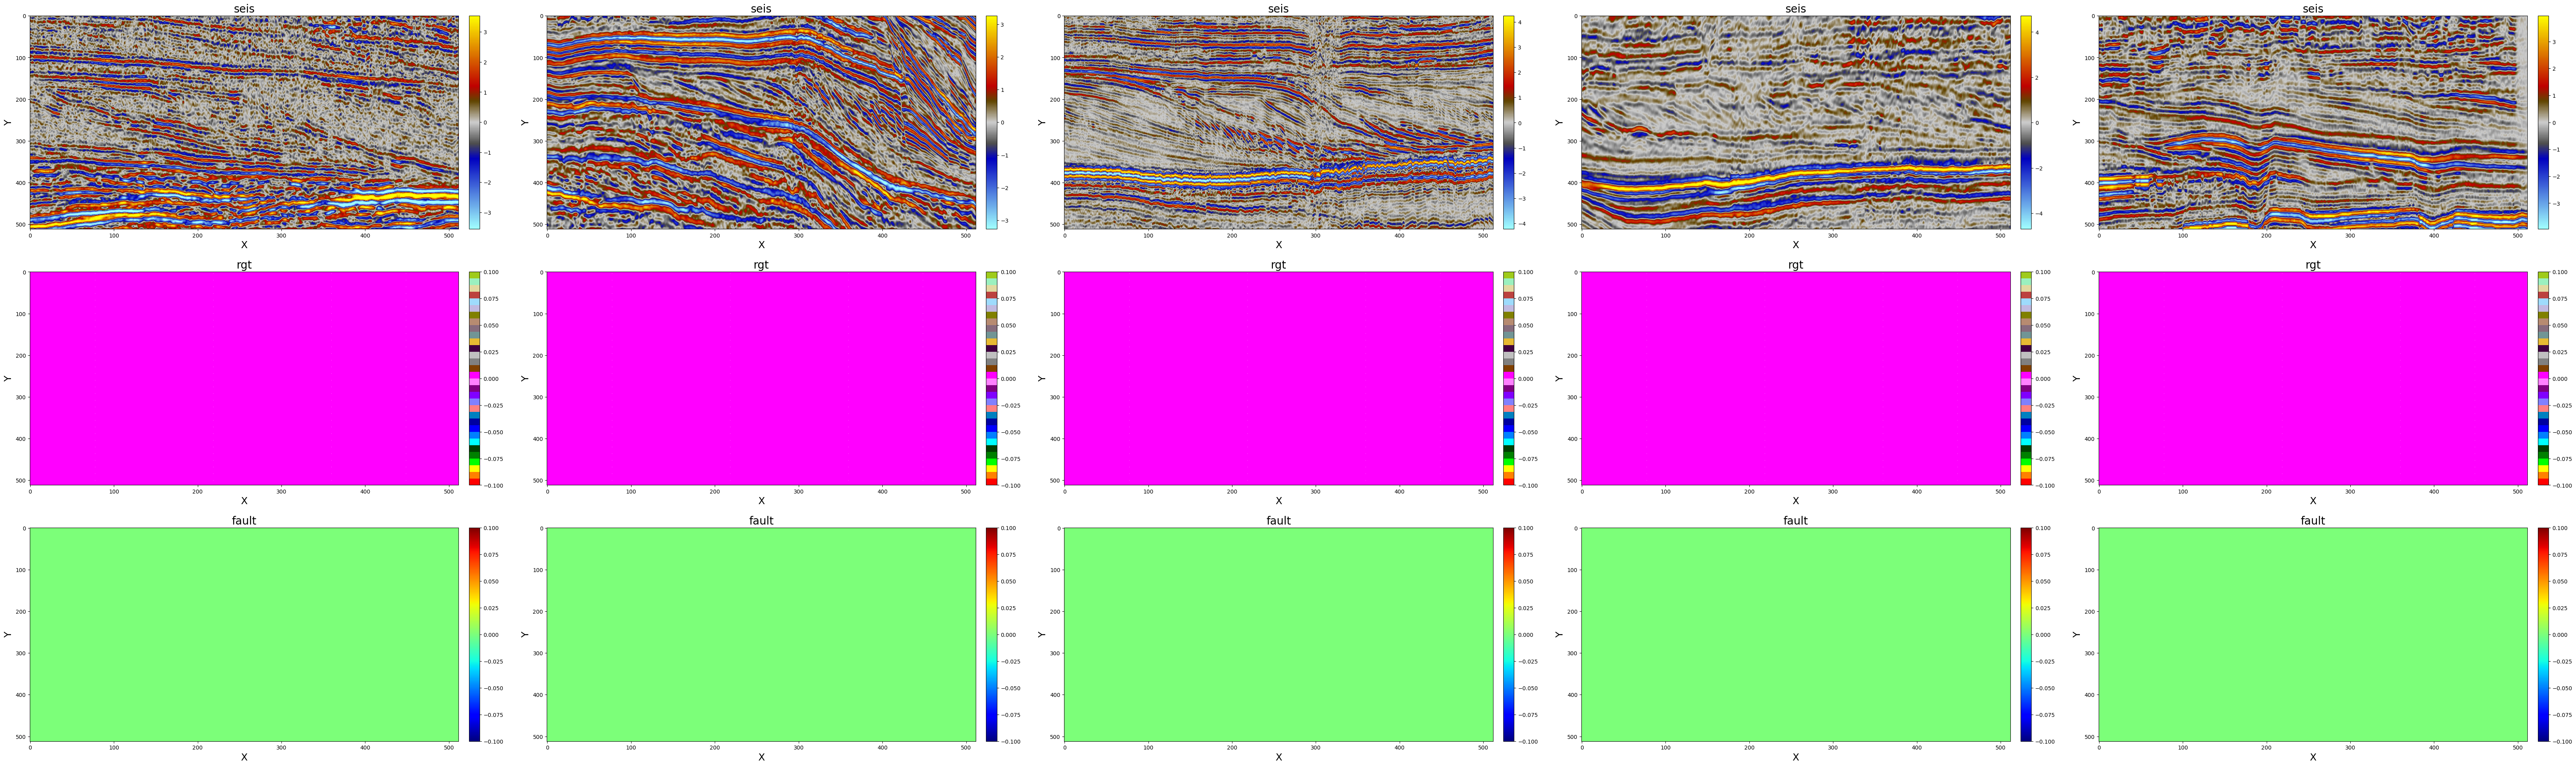

In [7]:
# plot
idxs = np.random.randint(0, len(train_data), size=5) 
batch_samples = [train_data[i] for i in idxs]
draw_attr_list = input_attr_list + rgt_attr_list + fault_attr_list
draw.draw_samples(batch_samples, draw_attr_list, cmap=[utils.getPetrelColors(),utils.getStrataColors(),"jet"],
                  methods=["bilinear","bilinear","nearest"])

In [8]:
model = models_mae.mae_vit_base_patch16_dec256d4b(img_size=512,in_chans=1)

model.load_state_dict(torch.load("./SFM_pretrain/SFM-Base-512.pth")["model"],strict=False)

# 并行模式
if torch.cuda.is_available():
    model = torch.nn.DataParallel(model, device_ids=range(num_GPU)).to(device)
else:
    model = model.to(device)

# 模型保存路径
checkpoint_path = os.path.join('checkpoints', Modelname)
if not os.path.exists(checkpoint_path):
    os.makedirs(checkpoint_path)
print(f"模型读取路径: {checkpoint_path}")

模型读取路径: checkpoints/Pretrain_field2d_base


In [9]:
# 定义训练参数
param = {}
param['epochs'] = 401     # 训练轮数
param['batch_size'] = 96   # 批大小
param['lr'] = 1e-3        # 学习率
# SGD
param['gamma'] = 0.9      # 学习率衰减系数
param['step_size'] = 50  # 学习率衰减间隔
param['momentum'] = 0.8    # 动量
# Adam
param['lr_factor'] = 0.5 # 学习因子
param['lr_patience'] = 2 # 容忍因子
param['weight_decay'] = 0 # 权重衰减(1e-4)

param['optimizer_type'] = 'Adam' # 优化器类型
param['checkpoint_path'] = checkpoint_path
param['disp_inter'] = 1 # 显示间隔
param['save_inter'] = 40 # 保存间隔

Epoch:0, Pretrain Loss:0.845167 Learning rate: 0.001000
Epoch:1, Pretrain Loss:0.543112 Learning rate: 0.001000
Epoch:2, Pretrain Loss:0.430257 Learning rate: 0.001000
Epoch:3, Pretrain Loss:0.393743 Learning rate: 0.001000
Epoch:4, Pretrain Loss:0.376903 Learning rate: 0.001000
Epoch:5, Pretrain Loss:0.366166 Learning rate: 0.001000
Epoch:6, Pretrain Loss:0.359675 Learning rate: 0.001000
Epoch:7, Pretrain Loss:0.353807 Learning rate: 0.001000
Epoch:8, Pretrain Loss:0.347287 Learning rate: 0.001000
Epoch:9, Pretrain Loss:0.345142 Learning rate: 0.001000
Epoch:10, Pretrain Loss:0.342763 Learning rate: 0.001000
Epoch:11, Pretrain Loss:0.339403 Learning rate: 0.001000
Epoch:12, Pretrain Loss:0.335786 Learning rate: 0.001000
Epoch:13, Pretrain Loss:0.333078 Learning rate: 0.001000
Epoch:14, Pretrain Loss:0.331420 Learning rate: 0.001000
Epoch:15, Pretrain Loss:0.329527 Learning rate: 0.001000
Epoch:16, Pretrain Loss:0.327390 Learning rate: 0.001000
Epoch:17, Pretrain Loss:0.324747 Learning

Epoch:144, Pretrain Loss:0.236568 Learning rate: 0.000500
Epoch:145, Pretrain Loss:0.236653 Learning rate: 0.000500
Epoch:146, Pretrain Loss:0.236087 Learning rate: 0.000500
Epoch:147, Pretrain Loss:0.236177 Learning rate: 0.000500
Epoch:148, Pretrain Loss:0.235381 Learning rate: 0.000500
Epoch:149, Pretrain Loss:0.235631 Learning rate: 0.000500
Epoch:150, Pretrain Loss:0.236090 Learning rate: 0.000500
Epoch:151, Pretrain Loss:0.235056 Learning rate: 0.000500
Epoch:152, Pretrain Loss:0.235350 Learning rate: 0.000500
Epoch:153, Pretrain Loss:0.234629 Learning rate: 0.000500
Epoch:154, Pretrain Loss:0.234086 Learning rate: 0.000500
Epoch:155, Pretrain Loss:0.233972 Learning rate: 0.000500
Epoch:156, Pretrain Loss:0.233659 Learning rate: 0.000500
Epoch:157, Pretrain Loss:0.233383 Learning rate: 0.000500
Epoch:158, Pretrain Loss:0.233400 Learning rate: 0.000500
Epoch:159, Pretrain Loss:0.233214 Learning rate: 0.000500
Epoch:160, Pretrain Loss:0.232852 Learning rate: 0.000500
Epoch:161, Pre

Epoch:286, Pretrain Loss:0.206395 Learning rate: 0.000000
Epoch:287, Pretrain Loss:0.206398 Learning rate: 0.000000
Epoch:288, Pretrain Loss:0.206806 Learning rate: 0.000000
Epoch:289, Pretrain Loss:0.207000 Learning rate: 0.000000
Epoch:290, Pretrain Loss:0.206886 Learning rate: 0.000000
Epoch:291, Pretrain Loss:0.206072 Learning rate: 0.000000
Epoch:292, Pretrain Loss:0.206127 Learning rate: 0.000000
Epoch:293, Pretrain Loss:0.206612 Learning rate: 0.000000
Epoch:294, Pretrain Loss:0.206500 Learning rate: 0.000000
Epoch:295, Pretrain Loss:0.206516 Learning rate: 0.000000
Epoch:296, Pretrain Loss:0.206228 Learning rate: 0.000000
Epoch:297, Pretrain Loss:0.206349 Learning rate: 0.000000
Epoch:298, Pretrain Loss:0.206500 Learning rate: 0.000000
Epoch:299, Pretrain Loss:0.206236 Learning rate: 0.000000
Epoch:300, Pretrain Loss:0.205857 Learning rate: 0.000000
Epoch:301, Pretrain Loss:0.206393 Learning rate: 0.000000
Epoch:302, Pretrain Loss:0.206729 Learning rate: 0.000000
Epoch:303, Pre

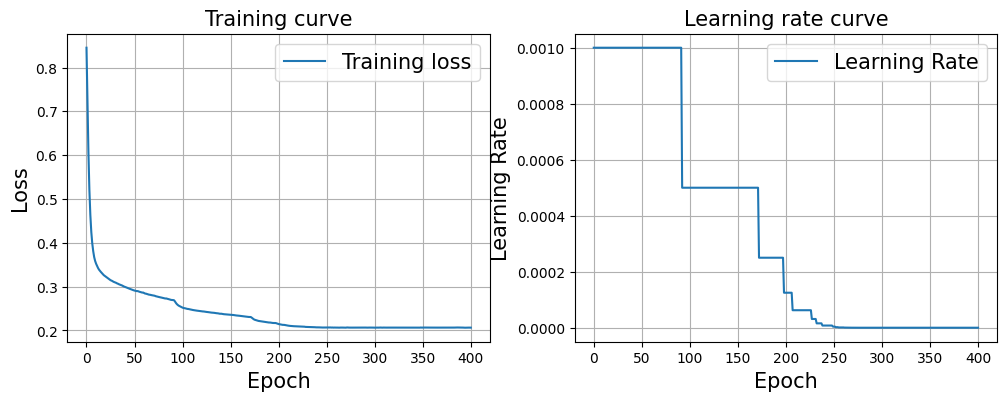

log has saved


In [10]:
model = utils.petrain_stage1(param, model, train_data, input_attrs=["seis"],
                             output_attrs=["rgt"],output_attrs2=["fault"],plot=True)

In [11]:
quit()